# Лабораторная работа 3. Транскрипция

Юдин Артём М4221

**Цель работы:** Разработка модуля преобразования графем в фонемы (G2P) на русском языке, подготовка фонетической транскрипции для обучения моделей.

По последовательности слов строится последовательность фонем из `common/phones_mfa.txt`. Пауза `<SIL>` проходит модуль без изменений.

Порог на test: PER связного текста не выше 0.025, PER слов, которых нет ни в train-словаре, ни в словаре Russian MFA, не выше 0.20.


# 1. Подготовка данных

Словесная и фонемная разметка -- общая MFA-разметка `data/RUSLAN_align_v2`. Нормализованный текст взят из первой работы. Каждый 5 пример переносится в test.

Фонема относится к слову, если её середина лежит внутри границ слова. Метка долготы `ː` снимается. Пустой интервал на уровне слов записывается токеном `<SIL>`. Если в фразе есть `spn`, фраза выбрасывается целиком. Словарь произношений считается только по train.


In [ ]:
from pathlib import Path

MFA_DICT_PATH = Path("data/russian_mfa.dict")
if not MFA_DICT_PATH.is_file():
    raise FileNotFoundError(
        "Не найден словарь Russian MFA: data/russian_mfa.dict.\n"
        "Скачайте Russian MFA dictionary v3.1.0 и положите файл в labs/lab3_g2p/data/:\n"
        "https://mfa-models.readthedocs.io/en/latest/dictionary/Russian/"
        "Russian%20MFA%20dictionary%20v3_1_0.html"
    )
print(f"Словарь MFA найден: {MFA_DICT_PATH.resolve()}")

In [1]:
import csv
import unicodedata
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from g2p import G2P, SIL, build_lexicon, calc_metrics, load_tokens, phone_error_rate


ALIGN_DIR = Path("../../data/RUSLAN_align_v2")
NORMALIZED_META = Path("../../data/metadata_RUSLAN_22200_normalized.csv")
PHONES_PATH = Path("../../common/phones_mfa.txt")


def lookup_word(token: str) -> str:
    text = unicodedata.normalize("NFC", str(token)).lower().strip()
    return "".join(char for char in text if char.isalpha() or char in "-'")


def allowed_phones() -> set[str]:
    phones = set()
    for line in PHONES_PATH.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#"):
            phones.update(line.split())
    phones.add(SIL)
    return phones


tokens = load_tokens()
train = tokens[tokens.set == "train"].copy()
test = tokens[tokens.set == "test"].copy()
lexicon = build_lexicon(train)
g2p = G2P(lexicon)
allowed = allowed_phones()

print(f"Фраз: {tokens.id.nunique()} (train {train.id.nunique()}, test {test.id.nunique()})")
print(f"Слов без пауз: {len(tokens)} (train {len(train)}, test {len(test)})")
print(f"Типов в train-словаре: {len(lexicon)}")
print(f"Из них с несколькими произношениями: {sum(len(item) > 1 for item in lexicon.values())}")
print(f"Слов в Russian MFA: {len(g2p.mfa_lexicon)}")


dropping 0 tokens without a transcription (0.00%)
Фраз: 19112 (train 15246, test 3866)
Слов без пауз: 212821 (train 169736, test 43085)
Типов в train-словаре: 37737
Из них с несколькими произношениями: 592
Слов в Russian MFA: 452359


# 2. Разведочный анализ

## 2.1. Какие фонемы есть в корпусе и как долго они звучат

Фонемы в разметке -- это IPA с пометками, которые MFA использует для русского. Мягкость записана либо знаком `ʲ`, либо отдельной фонемой (`ɲ`, `ʎ`, `c`, `ɟ`, `ç`, `ɕ`). Безударные гласные имеют собственные символы (`ɐ`, `ə`, `ɪ`, `ʊ`), поэтому отдельный знак ударения в списке не нужен.

Длительность ниже посчитана по интервалам уровня фонем в TextGrid, которые остались после фильтра.


In [2]:
#  читаем TextGrid и достаём интервалы
def iter_tier(path: Path, tier_name: str):
    in_tier = False
    xmin = xmax = None
    with path.open(encoding="utf-8") as handle:
        for raw in handle:
            line = raw.strip()
            if line.startswith("name ="):
                name = line.split("=", 1)[1].strip().strip('"')
                in_tier = name == tier_name
                xmin = xmax = None
                continue
            if not in_tier:
                continue
            if line.startswith("xmin ="):
                xmin = float(line.split("=", 1)[1])
            elif line.startswith("xmax ="):
                xmax = float(line.split("=", 1)[1])
            elif line.startswith("text ="):
                label = line.split("=", 1)[1].strip()
                if len(label) >= 2 and label[0] == '"' and label[-1] == '"':
                    label = label[1:-1]
                if xmin is not None and xmax is not None:
                    yield xmin, xmax, label
                xmin = xmax = None


# собираем длительности фонем
kept_ids = set(tokens.id)
durations: dict[str, list[float]] = defaultdict(list)
long_marks = 0
for path in sorted(ALIGN_DIR.glob("*.TextGrid")):
    if path.stem not in kept_ids:
        continue
    for start, end, label in iter_tier(path, "phones"):
        duration = end - start
        if "ː" in label:
            long_marks += 1
        phone = unicodedata.normalize("NFC", label).replace("ː", "")
        if phone in {"", "spn"}:
            phone = SIL if phone == "" else phone
        if phone == "spn":
            continue
        durations[phone].append(duration * 1000)

# записываем данные в таблицу
rows = []
for phone, values in durations.items():
    array = np.asarray(values)
    rows.append({"phone": phone, "count": int(array.size), "mean_ms": array.mean(), "std_ms": array.std()})
phone_stats = pd.DataFrame(rows).sort_values(["count", "phone"])
print(f"Фонем, включая <SIL>: {len(phone_stats)}")
print(f"Интервалов с меткой долготы ː: {long_marks}")
print(phone_stats.to_string(
    index=False,
    formatters={"mean_ms": "{:.0f}".format, "std_ms": "{:.0f}".format},
))


Фонем, включая <SIL>: 55
Интервалов с меткой долготы ː: 13785
phone  count mean_ms std_ms
    ʑ     19     130     24
    ɣ     21      52     28
   dʐ    221     151     31
   tʂ    272     147     29
    ç    466     143     33
    ɵ    924      85     49
   fʲ   1804     108     33
    ʉ   2328      39     33
    æ   3305      87     25
    ɟ   3446      92     33
   zʲ   3739     103     27
    ɕ   4501     148     30
   bʲ   4697      94     24
 t̪s̪   5511     133     39
   pʲ   5673      93     31
    ɛ   6493      91     38
    c   8511      97     29
    x   9953     108     37
   mʲ  10587      94     25
   vʲ  11031      72     30
    ʐ  11323      91     23
    ɡ  11812      78     25
   dʲ  11931      95     27
    f  11978      78     36
    ʂ  13198     119     31
   tɕ  14273     127     31
    b  14809      85     26
    u  16258      79     40
   z̪  17704      87     24
   rʲ  18776      68     26
   d̪  20032      72     23
   sʲ  20639     123     36
   tʲ  21611  

## 2.2. Самые редкие фонемы

Редкие фонемы в таблице выше остаются в рабочем списке. На PER корпуса они почти не влияют, потому что встречаются десятки раз на сотни тысяч фонем.

По длительности выделяются редуцированные `ɪ` и `ə`: они короткие. Дольше и разбросаннее всех пауза `<SIL>`.


In [3]:
phone_stats.head(10).to_string(
    index=False,
    formatters={"mean_ms": "{:.0f}".format, "std_ms": "{:.0f}".format},
)

'phone  count mean_ms std_ms\n    ʑ     19     130     24\n    ɣ     21      52     28\n   dʐ    221     151     31\n   tʂ    272     147     29\n    ç    466     143     33\n    ɵ    924      85     49\n   fʲ   1804     108     33\n    ʉ   2328      39     33\n    æ   3305      87     25\n    ɟ   3446      92     33'

## 2.3. Сколько слов не покрыто словарями

Слово считается словарным, если его строчная форма есть в train-словаре или в Russian MFA. Остаток -- слова, которых нет ни там, ни там. Именно на них смотрит второй порог работы.


In [4]:
def coverage(frame: pd.DataFrame) -> pd.Series:
    words = frame.token.map(lookup_word)
    in_train = words.isin(lexicon)
    in_mfa = words.isin(g2p.mfa_lexicon)
    return pd.Series({
        "train-словарь": int(in_train.sum()),
        "только MFA": int((~in_train & in_mfa).sum()),
        "ни в одном": int((~in_train & ~in_mfa).sum()),
        "всего": int(len(frame)),
    })

coverage_table = pd.DataFrame({"train": coverage(train), "test": coverage(test)})
print(coverage_table.to_string())
print(
    "Доля остатка на test: "
    f"{coverage_table.loc['ни в одном', 'test'] / coverage_table.loc['всего', 'test']:.1%}"
)


                train   test
train-словарь  169736  37409
только MFA          0   4451
ни в одном          0   1225
всего          169736  43085
Доля остатка на test: 2.8%


## 2.4. Что делает фильтр с аббревиатурами, сокращениями и числительными

Числительные и латиница убраны из текстов фильтром первой работы, в оставшихся TextGrid их нет. Часть аббревиатур была нормализована, другая отброшена фильтром.


In [5]:
normalized = pd.read_csv(
    NORMALIZED_META,
    sep="|",
    names=["id", "raw", "nrm"],
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)
normalized_ids = set(normalized.id)
raw_by_id = dict(zip(normalized.id, normalized.raw))
paths = sorted(ALIGN_DIR.glob("*.TextGrid"))
not_normalized = 0
spn_hits = []
other_dropped = []
for path in paths:
    utterance_id = path.stem
    if utterance_id in kept_ids:
        continue
    if utterance_id not in normalized_ids:
        not_normalized += 1
        continue
    words = list(iter_tier(path, "words"))
    phones = list(iter_tier(path, "phones"))
    bad_words = []
    for start, end, label in phones:
        if label != "spn":
            continue
        midpoint = (start + end) / 2
        owners = [word for w0, w1, word in words if word and w0 < midpoint < w1]
        bad_words.append(owners[0] if owners else "")
    if bad_words:
        spn_hits.append((utterance_id, bad_words))
    else:
        other_dropped.append(utterance_id)

print(f"TextGrid всего: {len(paths)}")
print(f"Осталось фраз: {len(kept_ids)}")
print(f"Не было после нормализации: {not_normalized}")
print(f"Удалено из-за spn: {len(spn_hits)}")
print(f"Прочие непрочитанные: {len(other_dropped)}")


TextGrid всего: 22199
Осталось фраз: 19112
Не было после нормализации: 897
Удалено из-за spn: 2190
Прочие непрочитанные: 0


Ниже -- примеры фраз, выброшенных из‑за `spn`. Печать идёт парами: слово, на котором выравниватель поставил `spn`, и исходный текст. Примеры отобраны по виду токена: слэш, дефис, скобки. Числительных и латиницы здесь нет — они уже отсеяны нормализацией первой работы; в `spn` попадают как раз оставшийся мусор разметки.

In [6]:
def show(predicate, limit):
    shown = 0
    for utterance_id, bad_words in spn_hits:
        if not predicate(bad_words):
            continue
        joined = ", ".join(word if word else SIL for word in bad_words)
        print(f"{utterance_id}: spn на [{joined}]")
        print("   ", raw_by_id.get(utterance_id, ""))
        shown += 1
        if shown >= limit:
            return


show(lambda words: any("/" in word for word in words), 2)
show(lambda words: any("-" in word or "‐" in word for word in words), 3)
show(lambda words: any(word in {"(", ")", "«", "»"} or word.startswith("(") for word in words), 2)


000880_RUSLAN: spn на [/библиография]
    Я на букву О /библиография к Окуджаве/.
004530_RUSLAN: spn на [/например]
    /Например, вертухай, как вы соизволили дружески меня поименовать.
003528_RUSLAN: spn на [селектрик-композер]
    Далее Мокер засыпал нас терминами айбиэм, процессор, селектрик-композер…
004608_RUSLAN: spn на [татаро-монголъское]
    А советская власть не татаро-монголъское иго.
004698_RUSLAN: spn на [судебно-наказуемое]
    Пособничество кэгэбэ судебно-наказуемое деяние.
007203_RUSLAN: spn на [(]
    Я надоила с одной коровы…» («…с одной коровы» я написал умышленно. 
007658_RUSLAN: spn на [где‐нибудь, (тогда]
    Ты кончишь свои дни где‑нибудь в Бразилии. (Тогда в семьдесят пятом году я засмеялся. 


## 2.5. Омографы: замок, все и всё

В целевом списке нет отдельного знака ударения. (По опыту - используется или знак `+`, как в руакценте и силеро стресс или в свдоенной букве)

Ударение на гласных видна в виде выбранной фонемы: ударные `a`, `o`, `e` отличаются от редуцированных `ɐ`, `ə`, `ɪ`. Выравниватель поэтому может хранить два чтения одного написания как две разные цепочки фонем.

Буква `ё` в нормализованном тексте часто записана как `е` (как и пояснялась в первой работе), так что `все` и `всё` приходят одним токеном. Словарь обучающей выборки хранит оба чтения. Модуль потом берёт самое частое и не выбирает чтение по соседним словам.


In [7]:
lexicon_df = pd.read_csv("data/lexicon.csv", sep="|", quoting=csv.QUOTE_NONE)
for word in ["замок", "все", "в", "уже"]:
    variants = lexicon_df[lexicon_df.word == word]
    print(variants.to_string(index=False))
    print()

minority = []
for word, group in lexicon_df.groupby("word"):
    if len(group) < 2:
        continue
    ordered = group.sort_values("count", ascending=False)
    minority.append({
        "word": word,
        "variants": len(group),
        "best": int(ordered.iloc[0]["count"]),
        "other": int(ordered["count"].iloc[1:].sum()),
    })
minority_df = pd.DataFrame(minority).sort_values("other", ascending=False)
print("Слова, у которых второе чтение встречается чаще всего:")
print(minority_df.head(10).to_string(index=False))


 word     phones  count
замок z̪ a m ə k      2
замок z̪ ɐ m o k      1

word phones  count
 все f sʲ ɵ    558
 все f sʲ e    343

word phones  count
   в      v   2494
   в      f   1741
   в    v ə    146
   в    v ɛ     23
   в     vʲ     10

word phones  count
 уже  u ʐ ɨ    205
 уже  ʊ ʐ ɛ     46

Слова, у которых второе чтение встречается чаще всего:
word  variants  best  other
   в         5  2494   1920
  на         2  1478    785
  из         4   338    386
 все         2   558    343
 что         2  1583    322
  не         3  2677    174
   с         6  1380    154
  то         2   381    151
 при         2    80     75
 уже         2   205     46


## 2.6. Как свести разметку к целевому списку

При предобработке долгота `ː` отбрасывается, пустая метка заменяется на `<SIL>`, фраза с `spn` удаляется. После этого каждая фонема в таблицах входит в целевой список. `d̪z̪` из списка в корпусе не встретилась, выдумывать для неё примеры не нужно.


In [8]:
observed = set(phone_stats.phone)
print("Есть в целевом списке и не встретились:", sorted(allowed - observed))
print("Встретились и не входят в целевой список:", sorted(observed - allowed))
print(f"Снято меток долготы: {long_marks}")


Есть в целевом списке и не встретились: ['d̪z̪']
Встретились и не входят в целевой список: []
Снято меток долготы: 13785


# 3. Модуль транскрипции

`G2P` для каждого токена делает одно и то же, слева направо:

1. самое частое произношение этого слова в `train`;
2. если слова нет в обучающей выборке -- самое вероятное произношение из Russian MFA 3.1;
3. если слова нет и там -- свои правила.

`<SIL>` возвращается как `["<SIL>"]` и в поиске по словарю не участвует. Регистр и знаки препинания снимаются только в момент поиска.

Правила для остатка включаются по шагам, атрибутом `oov_mode` уже после `G2P(lexicon)`:

| режим | что добавляется |
|---|---|
| `naive` | буква переводится в одну фонему, `ь` и `ъ` пропускаются |
| `soft` | мягкость перед `е ё и ю я` и `ь`; `е ё ю я` в начале слова, после гласной, `ь` или `ъ` дают `j` |
| `stress` | место ударения оценивается по похожим словам train, гласные редуцируются |
| `final` | оглушение и озвончение, одна фонема вместо двойной согласной, `лн` как `н`, `н` смягчается перед мягкими `т`/`д` |

Ударение для шагов `stress` и `final` берётся из train: сначала ищется слово с тем же началом, затем окончание, которое встречалось хотя бы три раза. `ё` само отмечает ударный слог. Готовая модель ударений не используется.


In [9]:
import contextlib
import io

import g2p as g2p_module

g2p_module.tqdm.tqdm = lambda iterable, **kwargs: iterable

sample = ["я", "вышел", "<SIL>", "из", "дома"]
print("пример:", sample, "->", g2p.transcribe(sample))

modes = [
    ("naive", "наивный"),
    ("soft", "+ смягчение"),
    ("stress", "+ ударение"),
    ("final", "финальный"),
]


def read_per(text: str, label: str) -> float:
    for line in text.splitlines():
        if line.startswith(label):
            parts = line.split()
            return float(parts[parts.index("PER") + 1])
    raise RuntimeError(f"нет строки {label}")


records = []
for mode, title in modes:
    g2p.oov_mode = mode
    for fold_name, fold in (("train", train), ("test", test)):
        buffer = io.StringIO()
        with contextlib.redirect_stdout(buffer):
            calc_metrics(g2p, fold, lexicon)
        printed = buffer.getvalue()
        records.append({
            "режим": title,
            "выборка": fold_name,
            "PER текста": read_per(printed, "running"),
            "PER остатка": read_per(printed, "residual"),
        })

metrics = pd.DataFrame(records)
print(metrics.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

final_test = metrics[(metrics["режим"] == "финальный") & (metrics["выборка"] == "test")].iloc[0]
assert final_test["PER текста"] <= 0.025
assert final_test["PER остатка"] <= 0.20
print(
    f"Пороги выполнены: PER текста {final_test['PER текста']:.4f}, "
    f"PER остатка {final_test['PER остатка']:.4f}"
)


пример: ['я', 'вышел', '<SIL>', 'из', 'дома'] -> [['j', 'a'], ['v', 'ɨ', 'ʂ', 'ɨ', 'ɫ'], ['<SIL>'], ['i', 'z̪'], ['d̪', 'o', 'm', 'ə']]
      режим выборка  PER текста  PER остатка
    наивный   train      0.0074          NaN
    наивный    test      0.0329       0.4958
+ смягчение   train      0.0074          NaN
+ смягчение    test      0.0252       0.3380
 + ударение   train      0.0074          NaN
 + ударение    test      0.0165       0.1589
  финальный   train      0.0074          NaN
  финальный    test      0.0152       0.1328
Пороги выполнены: PER текста 0.0152, PER остатка 0.1328


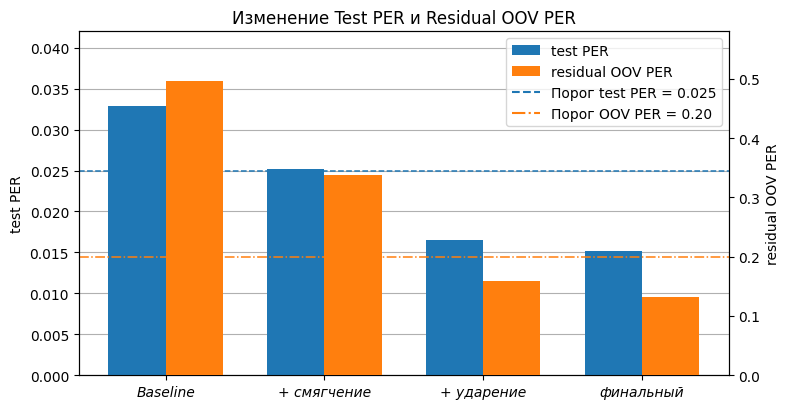

In [10]:
test_metrics = metrics[metrics["выборка"] == "test"].set_index("режим").loc[[title for _, title in modes]]
labels = ["Baseline", "+ смягчение", "+ ударение", "финальный"]
x = np.arange(len(labels))
width = 0.36

fig, ax_test = plt.subplots(figsize=(8, 4.2))
ax_residual = ax_test.twinx()
bars_test = ax_test.bar(
    x - width / 2,
    test_metrics["PER текста"],
    width,
    color="#1f77b4",
    zorder=3,
)
bars_residual = ax_residual.bar(
    x + width / 2,
    test_metrics["PER остатка"],
    width,
    color="#ff7f0e",
    zorder=3,
)
ax_test.axhline(0.025, color="#1f77b4", linestyle="--", linewidth=1.1, zorder=2)
ax_residual.axhline(0.20, color="#ff7f0e", linestyle="-.", linewidth=1.1, zorder=2)
ax_test.set_ylabel("test PER")
ax_residual.set_ylabel("residual OOV PER")
ax_test.set_xticks(x)
ax_test.set_xticklabels(labels, style="italic")
ax_test.set_ylim(0, 0.042)
ax_residual.set_ylim(0, 0.58)
ax_test.set_title("Изменение Test PER и Residual OOV PER")
ax_test.grid(True, axis="y", zorder=0)
ax_test.legend(
    [
        bars_test,
        bars_residual,
        plt.Line2D([0], [0], color="#1f77b4", linestyle="--"),
        plt.Line2D([0], [0], color="#ff7f0e", linestyle="-."),
    ],
    [
        "test PER",
        "residual OOV PER",
        "Порог test PER = 0.025",
        "Порог OOV PER = 0.20",
    ],
    loc="upper right",
)
fig.tight_layout()


# 4. Насколько омографы портят метрику

В тестовой выборке у части слов в обучающем словаре больше одного чтения. Модуль всегда берёт самое частое. Ниже даны доля таких слов, совпадение с разметкой и сколько из них совпало бы, если выбрать любой другой вариант из того же словаря.


In [11]:
g2p.oov_mode = "final"
ambiguous_ref = []
ambiguous_hyp = []
majority_ok = 0
oracle_ok = 0
for token, phones in zip(test.token.tolist(), test.phones.tolist()):
    variants = lexicon.get(token)
    if not variants or len(variants) < 2:
        continue
    reference = str(phones).split()
    hypothesis = g2p.transcribe([token])[0]
    ambiguous_ref.append(reference)
    ambiguous_hyp.append(hypothesis)
    majority_ok += int(hypothesis == reference)
    oracle_ok += int(any(variant.split() == reference for variant in variants))

ambiguous_n = len(ambiguous_ref)
print(f"Test-слов с несколькими чтениями в train: {ambiguous_n} ({ambiguous_n / len(test):.1%})")
print(f"PER на этих словах: {phone_error_rate(ambiguous_ref, ambiguous_hyp):.4f}")
print(f"Точное совпадение самого частого чтения: {majority_ok / ambiguous_n:.1%}")
print(f"Точное совпадение, если взять любой train-вариант: {oracle_ok / ambiguous_n:.1%}")


Test-слов с несколькими чтениями в train: 6946 (16.1%)
PER на этих словах: 0.0921
Точное совпадение самого частого чтения: 79.1%
Точное совпадение, если взять любой train-вариант: 99.8%


# 5. Метаданные для следующей работы

`data/metadata_phones_gt.csv` собирается из `tokens_phones_sil.csv`: одна фраза, текст из нормализованных метаданных, фонемы выравнивателя через пробел. `data/metadata_phones.csv` -- тот же текст, фонемы получены `G2P.transcribe`, включая `<SIL>`. Оба файла без заголовка, разделитель `|`.


In [12]:
def inventory_of(path: Path) -> tuple[int, list[str]]:
    used = set()
    rows = 0
    for line in path.open(encoding="utf-8"):
        rows += 1
        used.update(line.rstrip("\n").split("|")[2].split())
    return rows, sorted(used - allowed)


for name in ("../../data/metadata_phones_gt.csv", "../../data/metadata_phones.csv"):
    count, unknown = inventory_of(Path(name))
    print(f"{name}: {count} строк, фонем вне списка: {unknown}")


../../data/metadata_phones_gt.csv: 19112 строк, фонем вне списка: []
../../data/metadata_phones.csv: 19112 строк, фонем вне списка: []


# 6. Итог

Мы перевели слова в фонемный вид. Почти все слова находятся в обучающей выборке или в Russian MFA, остальное обрабатывается правилами. Основной выигрыш правил даёт оценка ударения и редукция гласных. Оглушение, двойные согласные и несколько сочетаний уменьшают ошибку остатка ещё немного.

Финальный режим укладывается в оба пороговых значения. Ошибку на словарных словах в основном дают омографы буква `э`. Мы в плане их обратки берём самое частое и не смотрит на контекст.
